# 5. Integration by parts and Watson's lemma

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 1 and 3

Part II is about integrals that depend on a large parameter $\lambda$: transforms,
special functions, partition functions, probabilities of rare events. Their
asymptotic behaviour is controlled by a few special points of the integrand, and
the methods of this part find those points and expand about them. This chapter
covers the simplest case, in which the integral is dominated by one endpoint. Two
tools do the work: repeated **integration by parts**, which generates the
expansions of the error function and the exponential integral, and **Watson's
lemma**, which turns the Taylor series of an integrand into the asymptotic series
of its Laplace transform.

In [1]:
import math

import matplotlib.pyplot as plt
import mpmath as mp
import numpy as np

try:
    import asymp as am
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import asymp as am

am.use_style()
mp.mp.dps = 40

## 5.1 Integration by parts: the error function

The complementary error function gives, for example, the temperature in a solid
whose surface is suddenly heated (Chapter 11),

$$ \operatorname{erfc} x = \frac{2}{\sqrt\pi}\int_x^\infty e^{-t^2}\,\mathrm dt . $$

For large $x$ the integrand falls off so fast that only the neighbourhood of the
lower limit matters. To make this precise, write $e^{-t^2} = -\frac{1}{2t}
\frac{\mathrm d}{\mathrm dt}e^{-t^2}$ and integrate by parts:

$$ \int_x^\infty e^{-t^2}\,\mathrm dt = \frac{e^{-x^2}}{2x}
   - \int_x^\infty \frac{e^{-t^2}}{2t^2}\,\mathrm dt . $$

The new integral is smaller than the old by a factor of order $1/x^2$, and the same
step can be repeated on it. Each repetition produces one more term,

$$ \operatorname{erfc} x \sim \frac{e^{-x^2}}{x\sqrt\pi}
   \sum_{n=0}^{\infty} (-1)^n \frac{(2n-1)!!}{(2x^2)^n}
   = \frac{e^{-x^2}}{x\sqrt\pi}\left(1 - \frac{1}{2x^2} + \frac{3}{4x^4} - \dots\right) , $$

the series used in Chapter 1. The remainder after $N$ terms is an integral of the
same form, which is how one proves that the error is smaller than the first
omitted term and has its sign. The method works because each step moves the
contribution to the endpoint $t = x$, where the integrand is largest.

The same steps applied to the **exponential integral**
$E_1(x) = \int_x^\infty e^{-t}\,t^{-1}\,\mathrm dt$, which appears in radiative
transfer and in transient well tests, give

$$ E_1(x) \sim \frac{e^{-x}}{x}\sum_{n=0}^{\infty}\frac{(-1)^n\,n!}{x^n} , $$

which is Euler's series of Chapter 1 with $x \to 1/x$. The cell checks both
expansions, measuring the slope of the relative error against $x$: with $N$ terms
it should be $-2N$ for $\operatorname{erfc}$ and $-N$ for $E_1$.

In [2]:
def erfc_series_scaled(x, N):
    """e^{x^2} erfc x from N terms of the series (the factor e^{-x^2} is taken out)."""
    s, t = 0.0, 1.0
    for n in range(N):
        if n > 0:
            t *= -(2 * n - 1) / (2 * x * x)
        s += t
    return s / (x * math.sqrt(math.pi))


def e1_series_scaled(x, N):
    """e^x E1(x) from N terms of the series."""
    s, t = 0.0, 1.0
    for n in range(N):
        if n > 0:
            t *= -n / x
        s += t
    return s / x


# compare the scaled functions: erfc(60) ~ 1e-1565 would underflow in double precision
xs_erfc = np.logspace(np.log10(3), np.log10(60), 25)
xs_e1 = np.logspace(np.log10(3), 3, 30)
erfc_ex = am.mp_map(lambda x: mp.erfc(x) * mp.exp(x * x), xs_erfc)
e1_ex = am.mp_map(lambda x: mp.e1(x) * mp.exp(x), xs_e1)
err_erfc = {N: np.abs(erfc_series_scaled(xs_erfc, N) / erfc_ex - 1) for N in (1, 2, 3, 4)}
err_e1 = {N: np.abs(e1_series_scaled(xs_e1, N) / e1_ex - 1) for N in (1, 2, 3, 4)}
for N in (1, 2, 3, 4):
    s1, p1 = am.loglog_slope(xs_erfc, err_erfc[N], fit_range=(15, 60))
    s2, p2 = am.loglog_slope(xs_e1, err_e1[N], fit_range=(200, 1000))
    print(f"N = {N}: relative error of erfc ~ {p1:.3g} x^{s1:.3f} (expected {math.prod(range(1, 2 * N, 2)) / 2**N:.3g} x^{-2 * N});"
          f"  of E1 ~ {p2:.3g} x^{s2:.3f} (expected {math.factorial(N)} x^{-N})")

N = 1: relative error of erfc ~ 0.495 x^-1.997 (expected 0.5 x^-2);  of E1 ~ 0.983 x^-0.998 (expected 1 x^-1)
N = 2: relative error of erfc ~ 0.734 x^-3.995 (expected 0.75 x^-4);  of E1 ~ 1.93 x^-1.995 (expected 2 x^-2)
N = 3: relative error of erfc ~ 1.82 x^-5.992 (expected 1.88 x^-6);  of E1 ~ 5.7 x^-2.993 (expected 6 x^-3)
N = 4: relative error of erfc ~ 6.34 x^-7.992 (expected 6.56 x^-8);  of E1 ~ 22.4 x^-3.991 (expected 24 x^-4)


The slopes are $-2N$ and $-N$, and the prefactors approach those of the first
omitted terms, $(2N-1)!!/2^N$ and $N!$; they are a little below them because the
next term has the opposite sign. The check is made on the functions scaled by
$e^{x^2}$ and $e^{x}$: at $x = 60$, $\operatorname{erfc} x \approx 10^{-1565}$ would
underflow in double precision. Since the error is a relative one, the
exponentially small factors $e^{-x^2}$ and $e^{-x}$, which no power series could
represent, cause no difficulty: they are taken out as prefactors, and the series
describes what multiplies them.

## 5.2 Watson's lemma

Most endpoint integrals can be written as Laplace transforms,

$$ I(\lambda) = \int_0^T g(t)\,e^{-\lambda t}\,\mathrm dt , \qquad \lambda \to \infty , $$

with $0 < T \le \infty$. For large $\lambda$ the factor $e^{-\lambda t}$ confines the
integral to $0 \le t \lesssim 1/\lambda$, so only the behaviour of $g$ near $t = 0$
can matter. Suppose $g$ has an expansion there in powers, not necessarily integer,

$$ g(t) \sim \sum_{k} g_k\,t^{\beta_k} , \qquad -1 < \beta_0 < \beta_1 < \dots $$

Integrating each term from 0 to $\infty$ (the error made by extending the range
beyond $T$, or beyond the radius of convergence of the series, is exponentially
small) with $\int_0^\infty t^\beta e^{-\lambda t}\,\mathrm dt = \Gamma(\beta+1)/\lambda^{\beta+1}$
gives **Watson's lemma**:

$$ I(\lambda) \sim \sum_k g_k\,\frac{\Gamma(\beta_k + 1)}{\lambda^{\beta_k + 1}} . $$

The expansion of the integrand near the endpoint becomes, term by term, the
expansion of the integral, with each power $t^\beta$ turned into $\Gamma(\beta+1)/\lambda^{\beta+1}$.
If the series of $g$ converges only for $t < t_0$, the series in $1/\lambda$
diverges: the Gamma functions grow factorially. This is the origin of the
divergence met in Chapters 1 and 4.

**An example with fractional powers.** Take

$$ I(\lambda) = \int_0^\infty \frac{e^{-\lambda t}}{1 + \sqrt t}\,\mathrm dt ,
   \qquad \frac{1}{1 + \sqrt t} = \sum_{k=0}^\infty (-1)^k t^{k/2} , $$

so that Watson's lemma gives a series in half-integer powers of $1/\lambda$,

$$ I(\lambda) \sim \sum_{k=0}^\infty (-1)^k\,\frac{\Gamma(k/2 + 1)}{\lambda^{k/2+1}}
   = \frac1\lambda - \frac{\sqrt\pi}{2\lambda^{3/2}} + \frac{1}{\lambda^2} - \dots $$

In [3]:
lams = np.logspace(1, 4, 25)
I_exact = np.array([am.mp_quad(lambda t, L=L: mp.exp(-L * t) / (1 + mp.sqrt(t)), 0, mp.inf) for L in lams])


def watson(lam, N):
    return sum((-1) ** k * math.gamma(k / 2 + 1) / lam ** (k / 2 + 1) for k in range(N))


err_w = {N: np.abs(watson(lams, N) - I_exact) for N in (1, 2, 3, 4, 5)}
ratio_w = {N: (I_exact - watson(lams, N)) / ((-1) ** N * math.gamma(N / 2 + 1) / lams ** (N / 2 + 1)) for N in (1, 2, 3, 4)}
for N in (1, 2, 3, 4, 5):
    s, _ = am.loglog_slope(lams, err_w[N], fit_range=(1e3, 1e4))
    print(f"N = {N} terms: error ~ lambda^{s:.3f}   (expected exponent {-(N / 2 + 1):.1f})")
print("error / first omitted term at lambda = 1e4: " + ", ".join(f"{ratio_w[N][-1]:.4f}" for N in (1, 2, 3, 4)))

N = 1 terms: error ~ lambda^-1.490   (expected exponent -1.5)
N = 2 terms: error ~ lambda^-1.988   (expected exponent -2.0)
N = 3 terms: error ~ lambda^-2.487   (expected exponent -2.5)
N = 4 terms: error ~ lambda^-2.985   (expected exponent -3.0)
N = 5 terms: error ~ lambda^-3.484   (expected exponent -3.5)
error / first omitted term at lambda = 1e4: 0.9889, 0.9869, 0.9852, 0.9837


Each term lowers the error by a factor of $\lambda^{1/2}$, as the half-integer
gauge requires, and the error divided by the first omitted term tends to 1. The
check confirms not only the size of the correction terms but their order: an
expansion that wrongly omitted the $\lambda^{-3/2}$ term would show a slope of $-3/2$
where $-2$ is expected.

## 5.3 When endpoints do not dominate

Integration by parts fails when the integrand is not largest at an endpoint.
For $\int_{-1}^{1} e^{-\lambda t^2}\,\mathrm dt$ the integrand is largest at $t = 0$,
in the interior, and an attempt to integrate by parts produces factors $1/t$
that are infinite there. Watson's lemma still applies after the substitution
$s = t^2$, which moves the maximum to an endpoint: $\int_0^1 s^{-1/2}e^{-\lambda s}\,\mathrm ds
\sim \Gamma(1/2)/\lambda^{1/2}$, that is $\sqrt{\pi/\lambda}$. Chapter 6 develops
this observation into Laplace's method, which handles interior maxima in general.

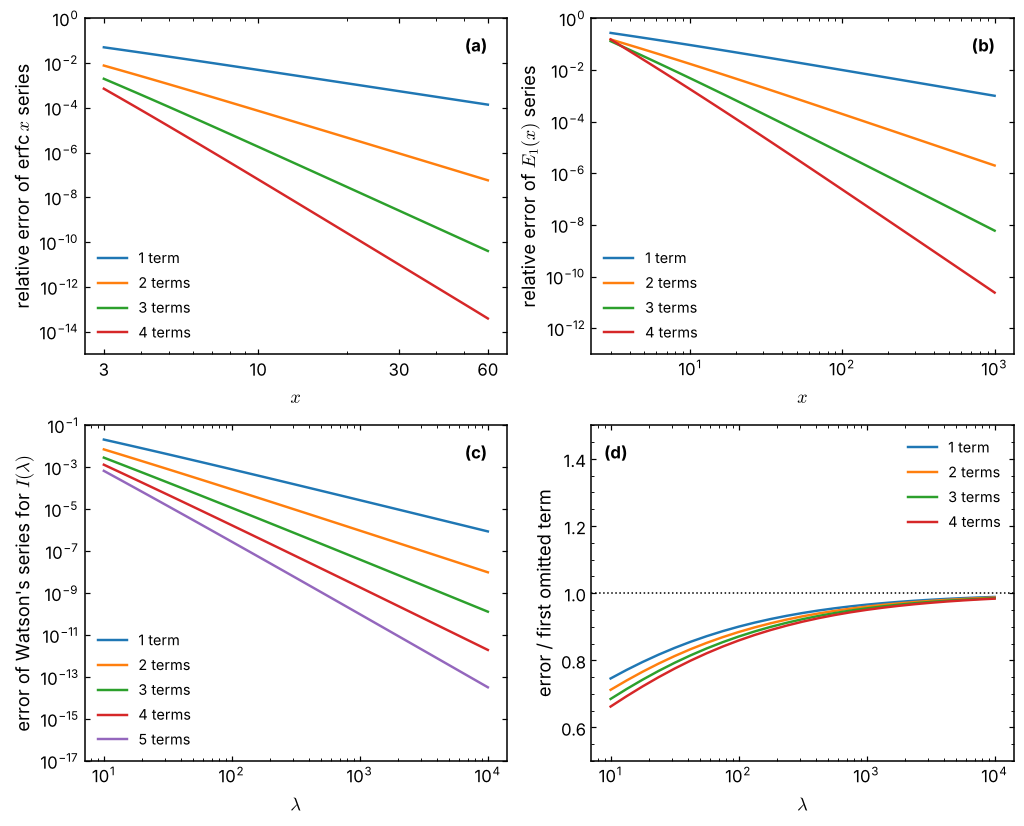

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))

ax = axes[0, 0]
for N, c in zip((1, 2, 3, 4), ("C0", "C1", "C2", "C3")):
    ax.loglog(xs_erfc, err_erfc[N], color=c, label=f"{N} term" + ("s" if N > 1 else ""))
ax.set_xticks([3, 10, 30, 60], ["3", "10", "30", "60"]); ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("$x$"); ax.set_ylabel(r"relative error of erfc$\,x$ series")
ax.set_ylim(1e-15, 1); ax.legend(loc="lower left"); am.panel_label(ax, "(a)", x=0.9)

ax = axes[0, 1]
for N, c in zip((1, 2, 3, 4), ("C0", "C1", "C2", "C3")):
    ax.loglog(xs_e1, err_e1[N], color=c, label=f"{N} term" + ("s" if N > 1 else ""))
ax.set_xlabel("$x$"); ax.set_ylabel(r"relative error of $E_1(x)$ series")
ax.set_ylim(1e-13, 1); ax.legend(loc="lower left"); am.panel_label(ax, "(b)", x=0.9)

ax = axes[1, 0]
for N, c in zip((1, 2, 3, 4, 5), ("C0", "C1", "C2", "C3", "C4")):
    ax.loglog(lams, err_w[N], color=c, label=f"{N} term" + ("s" if N > 1 else ""))
ax.set_xlabel(r"$\lambda$"); ax.set_ylabel(r"error of Watson's series for $I(\lambda)$")
ax.set_ylim(1e-17, 1e-1); ax.legend(loc="lower left"); am.panel_label(ax, "(c)", x=0.9)

ax = axes[1, 1]
for N, c in zip((1, 2, 3, 4), ("C0", "C1", "C2", "C3")):
    ax.semilogx(lams, ratio_w[N], color=c, label=f"{N} term" + ("s" if N > 1 else ""))
ax.axhline(1, color="k", ls=":", lw=1)
ax.set_xlabel(r"$\lambda$"); ax.set_ylabel("error / first omitted term")
ax.set_ylim(0.5, 1.5); ax.legend(loc="upper right"); am.panel_label(ax, "(d)")
plt.show()

**(a)** Relative error of the asymptotic series of $\operatorname{erfc} x$ with one to
four terms; slopes $-2, -4, -6, -8$. **(b)** The same for $E_1(x)$; slopes $-1$ to
$-4$. **(c)** Error of Watson's series for $\int_0^\infty e^{-\lambda t}/(1+\sqrt t)\,\mathrm dt$;
each term gains a factor $\lambda^{-1/2}$. **(d)** The same errors divided by the
first omitted term.

## Summary

* When an integrand is largest at an endpoint, repeated integration by parts
  generates its asymptotic series, and the remainder can be bounded.
* Watson's lemma: the expansion of $g(t)$ near $t = 0$ gives, term by term, the
  expansion of its Laplace transform, with $t^\beta \to \Gamma(\beta+1)/\lambda^{\beta+1}$.
* Fractional powers in $g$ give fractional powers in $1/\lambda$; the slope of the
  error checks that no term is missing.
* Exponential factors such as $e^{-x^2}$ are taken out before expanding; the series
  describes what multiplies them.

## Suggested references

* C. M. Bender and S. A. Orszag, *Advanced Mathematical Methods for Scientists
  and Engineers* (McGraw-Hill, 1978; Springer, 1999).
* N. Bleistein and R. A. Handelsman, *Asymptotic Expansions of Integrals* (Holt,
  Rinehart and Winston, 1975; Dover, 1986).
* E. J. Hinch, *Perturbation Methods* (Cambridge University Press, 1991).
* M. H. Holmes, *Introduction to Perturbation Methods*, 2nd ed. (Springer, 2013).
* F. W. J. Olver, *Asymptotics and Special Functions* (Academic Press, 1974;
  A K Peters, 1997).

## Exercises

1. Show that the remainder of the $\operatorname{erfc}$ series after $N$ terms is
   $(-1)^N\frac{(2N-1)!!}{2^N}\frac{2}{\sqrt\pi}\int_x^\infty t^{-2N}e^{-t^2}\,\mathrm dt$,
   and deduce that it is smaller than the first omitted term.
2. Use Watson's lemma to find three terms of $\int_0^\infty e^{-\lambda t}\ln(1+t)\,\mathrm dt$.
3. The incomplete gamma function $\Gamma(a, x) = \int_x^\infty t^{a-1}e^{-t}\,\mathrm dt$:
   derive its large-$x$ expansion at fixed $a$ and check it with `mpmath.gammainc`.
4. Expand $\int_0^1 e^{-\lambda t}\sqrt{t(1-t)}\,\mathrm dt$ for large $\lambda$. Why
   does the endpoint $t = 1$ not contribute to any order?

---

**Previous:** [4. Divergent series in practice](../part1_foundations/04_divergent_series_in_practice.ipynb) &nbsp;·&nbsp; **Next:** [6. Laplace's method](06_laplaces_method.ipynb)